# Capture-24: raw files to per-participant feature windows

Turns Capture-24 wrist recordings into the same 5 magnitude features used for the UCI-HAR model (`features.py`).
One parquet file per participant. Part 1 only prepares the data. **Part 2**, further down, trains and compares the models.

Steps, one participant at a time (the files are huge, so only one is ever in memory):

1. Load, then split into stretches that are labelled and have no time gap
2. Downsample each stretch from 100 Hz to 50 Hz
3. Cut each stretch into 128-sample windows with no overlap (2.56 s each)
4. Keep only windows with a single Walmsley2020 label
5. Compute features and save them with the label, participant ID, age bin and window start time

**Kernel:** needs pyarrow to write parquet. `anaconda4` has it, `anaconda3` does not.

**Splitting later:** always split by `participant_id`. Never put windows from one person in both train and test.

In [1]:
import gc
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow  # not used directly, but to_parquet needs it. If this fails, switch the kernel to anaconda4
from scipy.signal import butter, sosfiltfilt

from features import WIN, FEATURE_NAMES, magnitude, mag_features   # same feature code as UCI-HAR

## Settings

Change the participant list here. `PARTICIPANTS_OVERRIDE` takes an exact list, such as `['P001', 'P004']`, and skips the sampling rule.

In [2]:
DATA_DIR = Path('../../data/open datasets/capture24/capture24')
OUT_DIR = Path('../../data/processed/capture24_windows')

# who to process: everyone in OLDEST_BIN plus N_OTHERS random people from the other bins
OLDEST_BIN = '53+'
N_OTHERS = 8
SEED = 42
PARTICIPANTS_OVERRIDE = None

OVERWRITE = False   # False: skip participants that already have a parquet, so a stopped run can resume

LABEL_SCHEME = 'label:Walmsley2020'
LABELS = ['sleep', 'sedentary', 'light', 'moderate-vigorous']

RAW_HZ = 100
TARGET_HZ = 50
FACTOR = RAW_HZ // TARGET_HZ
RAW_WIN = WIN * FACTOR   # one 128-sample window at 50 Hz covers 256 raw samples
UNLABELLED = -1

## Choose participants

The list is sorted and the seed is fixed, so the same people are picked every time.

In [3]:
meta = pd.read_csv(DATA_DIR / 'metadata.csv').set_index('pid')

if PARTICIPANTS_OVERRIDE is not None:
    PARTICIPANTS = sorted(PARTICIPANTS_OVERRIDE)
else:
    oldest = sorted(meta.index[meta['age'] == OLDEST_BIN])
    others = sorted(meta.index[meta['age'] != OLDEST_BIN])
    picked = np.random.default_rng(SEED).choice(others, size=N_OTHERS, replace=False)
    PARTICIPANTS = sorted(oldest + [str(p) for p in picked])

print(len(PARTICIPANTS), 'participants:', PARTICIPANTS)
print(meta.loc[PARTICIPANTS, 'age'].value_counts().sort_index().to_string())

42 participants: ['P004', 'P007', 'P008', 'P009', 'P012', 'P015', 'P024', 'P029', 'P030', 'P039', 'P048', 'P053', 'P057', 'P058', 'P062', 'P064', 'P065', 'P067', 'P069', 'P076', 'P081', 'P083', 'P085', 'P092', 'P096', 'P098', 'P099', 'P101', 'P107', 'P111', 'P112', 'P117', 'P119', 'P122', 'P125', 'P129', 'P137', 'P138', 'P140', 'P142', 'P148', 'P150']
age
18-29     4
30-37     1
38-52     3
53+      34


## Processing functions

Three choices worth explaining:

- **Windows never cross a gap.** Simply deleting unlabelled rows would join stretches that were hours apart, and a window across that join would describe a movement that never happened. So each stretch is windowed on its own.
- **Filter before downsampling.** Keeping every second sample would let movement above 25 Hz fold back in as false lower-frequency signal (aliasing). So a 20 Hz low-pass goes first, the same cut-off UCI-HAR used. It runs forwards and backwards, so the signal is not shifted in time.
- **Butterworth, not `scipy.signal.decimate`.** The default `decimate` filter shrinks a steady signal by 1.14%, so a still wrist would read 0.989 g. That 11 mg error matters next to the 45 mg ENMO cut-point. Its FIR option is badly wrong at the start and end of each stretch. Butterworth leaves a steady 1 g at exactly 1 g, including at the edges.
- **Filter the x, y and z axes, then take the magnitude.** Magnitude is not a linear operation, so doing it the other way round gives a different signal. This is also the order used for UCI-HAR, whose `total_acc` axes are filtered first.

In [4]:
label_map = pd.read_csv(DATA_DIR / 'annotation-label-dictionary.csv', index_col='annotation')[LABEL_SCHEME]
label_code = {name: i for i, name in enumerate(LABELS)}
ANTI_ALIAS = butter(4, 20, fs=RAW_HZ, output='sos')   # 20 Hz low-pass


def annotations_to_codes(annotation):
    '''Categorical free-text annotations -> label codes, with UNLABELLED for missing rows.
    Stops with an error on unknown text, rather than quietly treating it as unlabelled.'''
    mapped = label_map.reindex(annotation.cat.categories)
    unknown = mapped.index[~mapped.isin(LABELS)].tolist()
    if unknown:
        raise ValueError(f'annotations with no {LABEL_SCHEME} label: {unknown}')
    code_of_category = mapped.map(label_code).to_numpy(np.int8)
    raw = annotation.cat.codes.to_numpy()
    return np.where(raw < 0, UNLABELLED, code_of_category[raw]).astype(np.int8)


def find_runs(codes, times_ns):
    '''(start, end) of each stretch that is labelled and has no time gap.
    A change of label does not end a stretch: that is real continuous signal, and mixed windows are removed later.'''
    period = 1e9 / RAW_HZ
    dt = np.diff(times_ns)
    labelled = codes != UNLABELLED
    breaks = np.flatnonzero((labelled[1:] != labelled[:-1]) | (dt > 1.5 * period) | (dt <= 0)) + 1
    starts = np.r_[0, breaks]
    ends = np.r_[breaks, len(codes)]
    return [(s, e) for s, e in zip(starts, ends) if labelled[s]]


def make_windows(times_ns, xyz, codes):
    '''Raw 100 Hz arrays -> features, label codes and start times of the single-label windows.'''
    feats, labels, starts = [], [], []
    n_runs = n_cut = 0
    for s, e in find_runs(codes, times_ns):
        n_runs += 1
        if e - s < RAW_WIN:      # too short to fill one window
            continue
        n_win = (e - s) // RAW_WIN
        n_cut += n_win

        xyz_50 = sosfiltfilt(ANTI_ALIAS, xyz[s:e], axis=0)[::FACTOR]
        mag = magnitude(xyz_50[:, 0], xyz_50[:, 1], xyz_50[:, 2])[:n_win * WIN].reshape(n_win, WIN)

        # check the label at full 100 Hz, so even a one-sample label change is caught
        win_codes = codes[s:s + n_win * RAW_WIN].reshape(n_win, RAW_WIN)
        single = (win_codes == win_codes[:, [0]]).all(axis=1)

        feats.append(mag_features(mag[single]))
        labels.append(win_codes[single, 0])
        starts.append(times_ns[s + np.flatnonzero(single) * RAW_WIN])

    if not feats:
        feats, labels, starts = [np.empty((0, len(FEATURE_NAMES)))], [np.empty(0, np.int8)], [np.empty(0, np.int64)]
    return (np.concatenate(feats), np.concatenate(labels), np.concatenate(starts),
            {'runs': n_runs, 'windows_cut': n_cut})


def process_participant(pid):
    '''Load one raw file, save one parquet, and return a summary row. Nothing is kept in memory afterwards.'''
    t0 = time.time()
    df = pd.read_csv(DATA_DIR / f'{pid}.csv.gz', usecols=['time', 'x', 'y', 'z', 'annotation'],
                     dtype={'x': float, 'y': float, 'z': float, 'annotation': 'category'},
                     parse_dates=['time'], date_format='ISO8601')
    if df[['time', 'x', 'y', 'z']].isna().any().any():
        raise ValueError('NaN in time or x/y/z')

    codes = annotations_to_codes(df['annotation'])
    times_ns = df['time'].to_numpy('datetime64[ns]').astype('int64')
    xyz = df[['x', 'y', 'z']].to_numpy()
    n_rows = len(df)
    del df

    X, y, starts, stats = make_windows(times_ns, xyz, codes)

    out = pd.DataFrame(X, columns=FEATURE_NAMES)
    out['label'] = np.array(LABELS, dtype=object)[y]
    out['participant_id'] = pid
    out['age_bin'] = meta.loc[pid, 'age']
    out['window_start'] = pd.to_datetime(starts)

    # write to a temp name first, so a crash can't leave a half-written file that looks finished
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    tmp = OUT_DIR / f'{pid}.parquet.tmp'
    out.to_parquet(tmp, engine='pyarrow', index=False)
    os.replace(tmp, OUT_DIR / f'{pid}.parquet')

    summary = {'pid': pid, 'age_bin': meta.loc[pid, 'age'], 'hours': n_rows / RAW_HZ / 3600,
               'unlabelled_pct': 100 * (codes == UNLABELLED).mean(), **stats,
               'windows_kept': len(out), 'mixed_dropped': stats['windows_cut'] - len(out),
               'seconds': time.time() - t0}
    del times_ns, xyz, codes, X, y, starts, out
    gc.collect()
    return summary

## Test the functions on fake data

These inputs have known answers, so a logic bug shows up here rather than silently ending up in the parquet files.

In [5]:
def fake_recording(n, label=0, start_ns=0):
    t = start_ns + np.arange(n) * 10_000_000   # 10 ms steps = 100 Hz
    xyz = np.tile([0.0, 0.0, 1.0], (n, 1))     # still sensor reading 1 g on one axis
    return t, xyz, np.full(n, label, np.int8)

# 1. a steady 1 g stays 1 g, including at the edges where filters can misbehave
t, xyz, c = fake_recording(RAW_WIN * 3 + 10)
X, y, s, st = make_windows(t, xyz, c)
assert st == {'runs': 1, 'windows_cut': 3} and len(X) == 3
assert np.allclose(X[:, FEATURE_NAMES.index('mag_mean')], 1, atol=1e-6)
assert np.allclose(X[:, FEATURE_NAMES.index('mag_std')], 0, atol=1e-6)
assert (s == t[[0, RAW_WIN, 2 * RAW_WIN]]).all()   # non-overlapping starts

# 2. an unlabelled gap splits the run: the two sides are windowed apart, not joined
c2 = c.copy()
c2[RAW_WIN + 100:RAW_WIN + 200] = UNLABELLED       # left: 356 samples, right: 322 samples, so 1 window each
X, y, s, st = make_windows(t, xyz, c2)
assert st['runs'] == 2 and len(X) == 2
assert s[1] == t[RAW_WIN + 200]                    # right side starts straight after the gap

# 3. a time gap splits the run too, even when both sides are labelled
t3 = t.copy()
t3[RAW_WIN + 50:] += 3_600_000_000_000             # jump forward 1 hour
assert make_windows(t3, xyz, c)[3]['runs'] == 2

# 4. a label change inside a window drops only that window, even a single raw sample
c4 = c.copy()
c4[RAW_WIN * 2 - 1] = 1                            # last raw sample of window 2
X, y, s, st = make_windows(t, xyz, c4)
assert st['windows_cut'] == 3 and len(X) == 2 and (s == t[[0, RAW_WIN * 2]]).all()

# 5. a run too short for a window gives nothing, and no crash
assert len(make_windows(*fake_recording(RAW_WIN - 1))[0]) == 0

# 6. the filter keeps slow movement and removes fast movement (gravity + a 5 Hz or 40 Hz wobble)
def wobble_std(freq):
    t, xyz, c = fake_recording(RAW_WIN * 10)
    xyz[:, 2] += 0.5 * np.sin(2 * np.pi * freq * np.arange(len(t)) / RAW_HZ)
    return make_windows(t, xyz, c)[0][3:7, FEATURE_NAMES.index('mag_std')].mean()
print(f'std with 5 Hz wobble: {wobble_std(5):.3f} (no filter loss = {0.5 / np.sqrt(2):.3f}), with 40 Hz wobble: {wobble_std(40):.5f}')
assert abs(wobble_std(5) - 0.5 / np.sqrt(2)) < 0.02
assert wobble_std(40) < 0.01

# 7. unknown annotation text stops with an error
try:
    annotations_to_codes(pd.Series(['not a real annotation'], dtype='category'))
    raise AssertionError('should have failed')
except ValueError:
    pass

print('all checks passed')

std with 5 Hz wobble: 0.353 (no filter loss = 0.354), with 40 Hz wobble: 0.00000
all checks passed


## Run

Roughly 25 seconds per participant. Stop it whenever you like and run it again: finished participants are skipped. A failure on one person is recorded and the rest still run.

In [6]:
summaries, failures = [], {}
t_start = time.time()
for i, pid in enumerate(PARTICIPANTS, 1):
    if (OUT_DIR / f'{pid}.parquet').exists() and not OVERWRITE:
        print(f'[{i}/{len(PARTICIPANTS)}] {pid} already done, skipping')
        continue
    try:
        row = process_participant(pid)
    except Exception as e:
        failures[pid] = repr(e)
        print(f'[{i}/{len(PARTICIPANTS)}] {pid} FAILED: {e!r}')
        continue
    summaries.append(row)
    print(f"[{i}/{len(PARTICIPANTS)}] {pid} ({row['age_bin']}): {row['windows_kept']} windows, "
          f"{row['mixed_dropped']} mixed dropped, {row['unlabelled_pct']:.1f}% unlabelled, {row['seconds']:.0f} s")

print(f'\nfinished in {(time.time() - t_start) / 60:.1f} min, failures: {failures or "none"}')
pd.DataFrame(summaries).round(2)

[1/42] P004 (53+): 21890 windows, 0 mixed dropped, 27.9% unlabelled, 24 s


[2/42] P007 (53+): 29577 windows, 0 mixed dropped, 24.7% unlabelled, 32 s


[3/42] P008 (53+): 25846 windows, 0 mixed dropped, 30.8% unlabelled, 30 s


[4/42] P009 (53+): 8821 windows, 0 mixed dropped, 69.0% unlabelled, 22 s


[5/42] P012 (53+): 26745 windows, 0 mixed dropped, 27.4% unlabelled, 29 s


[6/42] P015 (18-29): 21461 windows, 0 mixed dropped, 41.2% unlabelled, 29 s


... (33 outputs left out)

[40/42] P142 (53+): 15246 windows, 0 mixed dropped, 34.3% unlabelled, 20 s


[41/42] P148 (38-52): 24212 windows, 0 mixed dropped, 34.7% unlabelled, 28 s


[42/42] P150 (38-52): 29032 windows, 1 mixed dropped, 22.6% unlabelled, 32 s

finished in 19.0 min, failures: none


,pid,age_bin,hours,unlabelled_pct,runs,windows_cut,windows_kept,mixed_dropped,seconds
0,P004,53+,21.64,27.94,75,21890,21890,0,24.22
1,P007,53+,28.00,24.72,135,29577,29577,0,31.92
2,P008,53+,26.63,30.81,112,25846,25846,0,29.58
3,P009,53+,20.30,69.00,64,8821,8821,0,21.50
4,P012,53+,26.25,27.42,102,26745,26745,0,29.33
5,P015,18-29,26.00,41.17,102,21461,21461,0,28.72
6,P024,53+,28.00,27.60,132,28433,28433,0,31.42
7,P029,53+,28.00,41.56,93,22963,22963,0,30.58
8,P030,53+,27.00,20.17,56,30282,30282,0,30.14
9,P039,53+,25.50,44.60,148,19784,19784,0,25.23


## Check what was saved

Reads the parquet files back from disk, so this checks the saved files and not the variables above.

In [7]:
missing = [p for p in PARTICIPANTS if not (OUT_DIR / f'{p}.parquet').exists()]
print('participants with no parquet:', missing or 'none')
windows = pd.concat([pd.read_parquet(OUT_DIR / f'{p}.parquet') for p in PARTICIPANTS if p not in missing], ignore_index=True)

# one parquet = one person, with the right age bin
for pid, g in windows.groupby('participant_id'):
    assert g['age_bin'].nunique() == 1 and g['age_bin'].iloc[0] == meta.loc[pid, 'age'], pid
    # non-overlapping: starts are at least one window (2.56 s) apart
    assert g['window_start'].diff().dropna().min() >= pd.Timedelta(seconds=WIN / TARGET_HZ), pid

assert list(windows.columns) == FEATURE_NAMES + ['label', 'participant_id', 'age_bin', 'window_start']
assert windows[FEATURE_NAMES].notna().all().all()
assert set(windows['label']) <= set(LABELS)
tol = 1e-9   # a perfectly flat window can differ from its own mean by floating-point rounding
assert (windows['mag_min'] <= windows['mag_mean'] + tol).all() and (windows['mag_mean'] <= windows['mag_max'] + tol).all()

print(f"{len(windows):,} windows ({len(windows) * WIN / TARGET_HZ / 3600:.0f} hours) from {windows['participant_id'].nunique()} participants")
print('participants per age bin:', windows.groupby('age_bin')['participant_id'].nunique().to_dict())

print('\nwindows per class:')
counts = windows['label'].value_counts().reindex(LABELS)
print(pd.DataFrame({'windows': counts, 'percent': (100 * counts / counts.sum()).round(2)}).to_string())

print('\npercent of windows per class, by age bin:')
print((pd.crosstab(windows['age_bin'], windows['label'], normalize='index')[LABELS] * 100).round(2).to_string())

print('\nwindows per participant:')
print(windows.groupby('participant_id').size().describe().round(0).to_string())

print('\nparticipants with very few moderate-vigorous windows (matters for splitting later):')
mv = windows[windows['label'] == 'moderate-vigorous'].groupby('participant_id').size().reindex(PARTICIPANTS, fill_value=0)
print(mv.describe().round(0).to_string())
print('with fewer than 10:', int((mv < 10).sum()))

print('\nmean feature values per class (a still wrist should have mag_mean near 1 g and a small mag_std):')
print(windows.groupby('label')[FEATURE_NAMES].mean().reindex(LABELS).round(3).to_string())

participants with no parquet: none


984,131 windows (700 hours) from 42 participants
participants per age bin: {'18-29': 4, '30-37': 1, '38-52': 3, '53+': 34}

windows per class:


                   windows  percent
label                              
sleep               334163    33.96
sedentary           400242    40.67
light               189930    19.30
moderate-vigorous    59796     6.08

percent of windows per class, by age bin:


label    sleep  sedentary  light  moderate-vigorous
age_bin                                            
18-29    38.91      36.25  17.82               7.03
30-37    38.46      31.29  29.95               0.30
38-52    37.89      36.41  14.80              10.90
53+      32.92      41.83  19.57               5.69

windows per participant:
count       42.0
mean     23432.0
std       5039.0
min       8821.0
25%      21503.0
50%      23856.0
75%      27107.0
max      30576.0

participants with very few moderate-vigorous windows (matters for splitting later):
count      42.0
mean     1424.0
std      1673.0
min         0.0
25%       227.0
50%       772.0
75%      1927.0
max      6982.0
with fewer than 10: 4

mean feature values per class (a still wrist should have mag_mean near 1 g and a small mag_std):


                   mag_mean  mag_std  mag_min  mag_max  mag_range
label                                                            
sleep                 0.999    0.006    0.982    1.021      0.039
sedentary             1.002    0.040    0.892    1.158      0.267
light                 1.030    0.141    0.713    1.528      0.815
moderate-vigorous     1.085    0.263    0.564    2.029      1.466


## What happened, in plain language

A machine learning model can't learn from millions of raw sensor readings directly, so this notebook turns them into a neat table it can learn from later. Capture-24 recorded people's wrist movement 100 times a second for about a day each, and people also noted what they were doing, such as sleeping or walking. For each person, the notebook loads their file, throws away the parts with no activity note, and slows the signal from 100 to 50 readings per second to match UCI-HAR and the SilverGuard sensor. It filters the signal first, so that very fast vibrations don't get mixed in and distort it. It then cuts the signal into short clips of 2.56 seconds called *windows*, and sums up each one in 5 numbers using your `features.py`: the average, spread, minimum, maximum and range of the movement strength. A still wrist reads about 1 g from gravity alone, so a resting window has a mean near 1 and a very small spread, while an active window varies a lot more. Each window also gets a label (sleep, sedentary, light or moderate-vigorous), and each person's windows are saved to their own parquet file, a compact table format.

The result is 984,131 windows, about 700 hours, from 42 people: all 34 in the oldest group (53+) and 8 picked at random from the younger groups. The split is 34% sleep, 41% sedentary, 19% light and 6% moderate-vigorous. The table at the end backs this up: average spread rises steadily from sleep (0.006) to moderate-vigorous (0.263), so the 5 numbers do carry information about activity. **Nothing is trained in this part.** It only prepares the data. Part 2 below trains a model on some people and tests it on different people. Windows from one person look alike, so if the same person appeared in both groups, the model could recognise them instead of the activity, and its score would look better than it really is. That is why `participant_id` is saved with every window.

# Part 2: still vs moving, comparing three models

The question: on the same unseen people, how do these compare?

- **UCI model:** the existing `rf_mag_uci.joblib`, loaded unchanged. It has never seen Capture-24.
- **Capture-24 model:** a new forest with the same settings, trained on Capture-24.
- **Threshold baseline:** one cut-off on `mag_std`. If a model can't beat this, its extra complexity isn't earning anything.

Nothing is tuned. This part can run on its own, without rerunning Part 1.

**Why two Pythons:** `rf_mag_uci.joblib` was saved with scikit-learn 1.2.2 (`anaconda3`). This notebook needs pyarrow, which only `anaconda4` has, and its scikit-learn 1.7.2 can't open the old file. Converting the file would mean it's no longer the same model, so the notebook asks `anaconda3` to run it and just collects the predictions.

In [1]:
import json
import os
import subprocess
import tempfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, recall_score
from sklearn.model_selection import StratifiedShuffleSplit

from features import FEATURE_NAMES

PARQUET_DIR = Path('../../data/processed/capture24_windows')
UCI_MODEL_PATH = Path('rf_mag_uci.joblib')
UCI_PYTHON = Path(r'C:\Users\syafi\anaconda3\python.exe')   # the Python that saved the UCI model
C24_MODEL_PATH = Path('rf_mag_capture24.joblib')
TEST_LIST_PATH = Path('capture24_test_participants.csv')

TEST_FRACTION = 0.25
SPLIT_SEED = 42
OLDER_BIN = '53+'

# sleep is dropped, then 0 = still, 1 = moving
TO_BINARY = {'sedentary': 0, 'light': 1, 'moderate-vigorous': 1}
CLASS_NAMES = ['still', 'moving']

## Load the windows

Sleep is removed and the rest becomes still (0) or moving (1).

In [2]:
files = sorted(PARQUET_DIR.glob('P*.parquet'))
data = pd.concat([pd.read_parquet(f, columns=FEATURE_NAMES + ['label', 'participant_id', 'age_bin']) for f in files],
                 ignore_index=True)

data = data[data['label'] != 'sleep'].reset_index(drop=True)
data['y'] = data['label'].map(TO_BINARY)
assert data['y'].notna().all()   # every remaining label must be in TO_BINARY
data['y'] = data['y'].astype(int)

print(f"{len(data):,} windows from {data['participant_id'].nunique()} participants (sleep removed)")
print(data['y'].map({0: 'still', 1: 'moving'}).value_counts().to_string())

649,968 windows from 42 participants (sleep removed)
y
still     400242
moving    249726


## Step 1: split by participant, once

Whole people go into train or test, so the score shows how the model does on someone it has never seen.

Each person is put in a group by age (53+ or younger) and by moving windows (above or below the median), and about 25% of each group is held out. That guarantees the test set has 53+ people and people with plenty of movement.

The list is saved, and later runs **reuse the saved file**, so the test set can't drift. To make a new split, delete the file, though at that point the old test people have already influenced your decisions.

In [3]:
people = data.groupby('participant_id').agg(age_bin=('age_bin', 'first'), windows=('y', 'size'), moving_windows=('y', 'sum'))
people['older'] = people['age_bin'] == OLDER_BIN
people['many_moving'] = people['moving_windows'] >= people['moving_windows'].median()
people['stratum'] = np.where(people['older'], '53+', 'younger') + ' / ' + np.where(people['many_moving'], 'more moving', 'less moving')

if TEST_LIST_PATH.exists():
    test_ids = pd.read_csv(TEST_LIST_PATH)['participant_id'].tolist()
    print(f'reusing the saved split in {TEST_LIST_PATH}')
else:
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=SPLIT_SEED)
    _, test_idx = next(splitter.split(people, people['stratum']))
    test_ids = sorted(people.index[test_idx])
    people.loc[test_ids, ['age_bin', 'stratum', 'windows', 'moving_windows']].reset_index().to_csv(TEST_LIST_PATH, index=False)
    print(f'new split saved to {TEST_LIST_PATH}')

train_ids = sorted(set(people.index) - set(test_ids))

# never one person in both
assert set(train_ids).isdisjoint(test_ids)
assert set(train_ids) | set(test_ids) == set(people.index)

is_test = data['participant_id'].isin(test_ids)
train, test = data[~is_test], data[is_test].reset_index(drop=True)
assert set(train['participant_id']).isdisjoint(test['participant_id'])

print(f'train: {len(train_ids)} people, {len(train):,} windows, {train["y"].mean():.1%} moving')
print(f'test:  {len(test_ids)} people, {len(test):,} windows, {test["y"].mean():.1%} moving')
print('\npeople per group (train / test):')
print(pd.crosstab(people['stratum'], people.index.isin(test_ids)).rename(columns={False: 'train', True: 'test'}).to_string())
print('\ntest participants:')
print(people.loc[test_ids, ['age_bin', 'windows', 'moving_windows']].to_string())

new split saved to capture24_test_participants.csv


train: 31 people, 478,877 windows, 38.5% moving
test:  11 people, 171,091 windows, 38.2% moving

people per group (train / test):
col_0                  train  test
stratum                           
53+ / less moving         13     4
53+ / more moving         12     5
younger / less moving      3     1
younger / more moving      3     1

test participants:
               age_bin  windows  moving_windows
participant_id                                 
P012               53+    16785            9009
P057               53+    15979            4626
P064               53+    15350            7177
P076               53+    19426           13391
P081               53+     7103            2729
P092               53+    17281            2696
P096             18-29    20080            3331
P107             38-52    15340            5186
P111               53+    19052            3714
P117               53+    12674            6478
P137               53+    12021            6983


## Steps 2 and 3: the two forests

The UCI model's settings are read from the saved file instead of being retyped, so the two forests are guaranteed to match. The features go in as plain arrays in `FEATURE_NAMES` order, the same way the UCI model was trained.

In [4]:
X_train, y_train = train[FEATURE_NAMES].to_numpy(), train['y'].to_numpy()
X_test, y_test = test[FEATURE_NAMES].to_numpy(), test['y'].to_numpy()


def run_in_uci_python(script, *args):
    '''Run a short script in the Python that saved the UCI model and return what it printed.'''
    env = dict(os.environ)
    root = UCI_PYTHON.parent
    env['PATH'] = os.pathsep.join([str(root), str(root / 'Library' / 'bin'), str(root / 'Scripts'), env.get('PATH', '')])
    done = subprocess.run([str(UCI_PYTHON), '-c', script, *map(str, args)], capture_output=True, text=True, env=env)
    if done.returncode != 0:
        raise RuntimeError(done.stderr)
    return done.stdout


READ_INFO = '''
import json, sys, joblib, sklearn
m = joblib.load(sys.argv[1])
print(json.dumps({'sklearn': sklearn.__version__, 'classes': m.classes_.tolist(), 'n_features': int(m.n_features_in_), 'params': m.get_params()}))
'''

PREDICT = '''
import sys, joblib, numpy as np
m = joblib.load(sys.argv[1])
np.save(sys.argv[3], m.predict(np.load(sys.argv[2])))
'''

uci_info = json.loads(run_in_uci_python(READ_INFO, UCI_MODEL_PATH.resolve()))
print('UCI model: scikit-learn', uci_info['sklearn'], '| classes', uci_info['classes'], '| features', uci_info['n_features'])
assert uci_info['classes'] == [0, 1]                    # 0 = resting -> still, 1 = walking -> moving
assert uci_info['n_features'] == len(FEATURE_NAMES)

# step 2: same settings, Capture-24 training people
c24_model = RandomForestClassifier(**uci_info['params'])
c24_model.fit(X_train, y_train)
joblib.dump(c24_model, C24_MODEL_PATH)
print('settings:', {k: uci_info['params'][k] for k in ['n_estimators', 'max_depth', 'max_features', 'min_samples_leaf', 'class_weight', 'random_state']})
print('saved', C24_MODEL_PATH)
print('\nCapture-24 model, what it relies on:')
print(pd.Series(c24_model.feature_importances_, index=FEATURE_NAMES).round(3).to_string())

# step 3: UCI model, unchanged. Its 0/1 already mean resting/walking, so no remapping is needed
with tempfile.TemporaryDirectory() as tmp:
    x_file, pred_file = Path(tmp) / 'x.npy', Path(tmp) / 'pred.npy'
    np.save(x_file, X_test)
    run_in_uci_python(PREDICT, UCI_MODEL_PATH.resolve(), x_file, pred_file)
    uci_pred = np.load(pred_file)
assert len(uci_pred) == len(y_test)

UCI model: scikit-learn 1.2.2 | classes [0, 1] | features 5


settings: {'n_estimators': 10, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'class_weight': None, 'random_state': 42}
saved rf_mag_capture24.joblib

Capture-24 model, what it relies on:
mag_mean     0.065
mag_std      0.437
mag_min      0.071
mag_max      0.250
mag_range    0.177


## Step 4: threshold baseline

Predict moving when `mag_std` is above one cut-off. The cut-off is chosen on training people only, in the same way as `test_har70plus.ipynb`: try 199 candidates and keep the one with the best accuracy.

In [5]:
train_std = train['mag_std'].to_numpy()
candidates = np.quantile(train_std, np.linspace(0.01, 0.99, 199))
train_acc = [((train_std > c).astype(int) == y_train).mean() for c in candidates]
cutoff = candidates[int(np.argmax(train_acc))]
print(f'mag_std cutoff (from training people only): {cutoff:.4f} g, training accuracy {max(train_acc):.3f}')

threshold_pred = (test['mag_std'].to_numpy() > cutoff).astype(int)

mag_std cutoff (from training people only): 0.0955 g, training accuracy 0.786


## Step 5: scores on the same test people

- **Accuracy:** share of all windows that were right. It flatters models that favour the bigger class.
- **Balanced accuracy:** the average of the two recalls, so both classes count equally.
- **Moving recall:** of the truly moving windows, the share caught.
- **Still recall:** of the truly still windows, the share caught.

In [6]:
predictions = {
    'UCI model': uci_pred,
    'Capture-24 model': c24_model.predict(X_test),
    'Threshold baseline': threshold_pred,
}


def scores(y, pred):
    return {'accuracy': accuracy_score(y, pred),
            'balanced accuracy': balanced_accuracy_score(y, pred),
            'moving recall': recall_score(y, pred, pos_label=1),
            'still recall': recall_score(y, pred, pos_label=0)}


older = (test['age_bin'] == OLDER_BIN).to_numpy()
results = pd.DataFrame({name: {**{('All test participants', k): v for k, v in scores(y_test, p).items()},
                               **{(f'{OLDER_BIN} only', k): v for k, v in scores(y_test[older], p[older]).items()}}
                        for name, p in predictions.items()}).T
results.columns = pd.MultiIndex.from_tuples(results.columns)

print(f'all test participants: {test["participant_id"].nunique()} people, {len(test):,} windows')
print(f'{OLDER_BIN} only: {test.loc[older, "participant_id"].nunique()} people, {older.sum():,} windows')
print(f'for reference, always answering "still" would score accuracy {(y_test == 0).mean():.3f}, balanced accuracy 0.500')
results.round(3)

all test participants: 11 people, 171,091 windows
53+ only: 9 people, 135,671 windows
for reference, always answering "still" would score accuracy 0.618, balanced accuracy 0.500


All test participants                                  \
                                accuracy balanced accuracy moving recall   
UCI model                          0.760             0.733         0.619   
Capture-24 model                   0.769             0.739         0.609   
Threshold baseline                 0.767             0.736         0.603   

                                53+ only                                  \
                   still recall accuracy balanced accuracy moving recall   
UCI model                 0.847    0.754             0.733         0.601   
Capture-24 model          0.868    0.760             0.736         0.590   
Threshold baseline        0.868    0.759             0.734         0.586   

                                 
                   still recall  
UCI model                 0.865  
Capture-24 model          0.882  
Threshold baseline        0.883

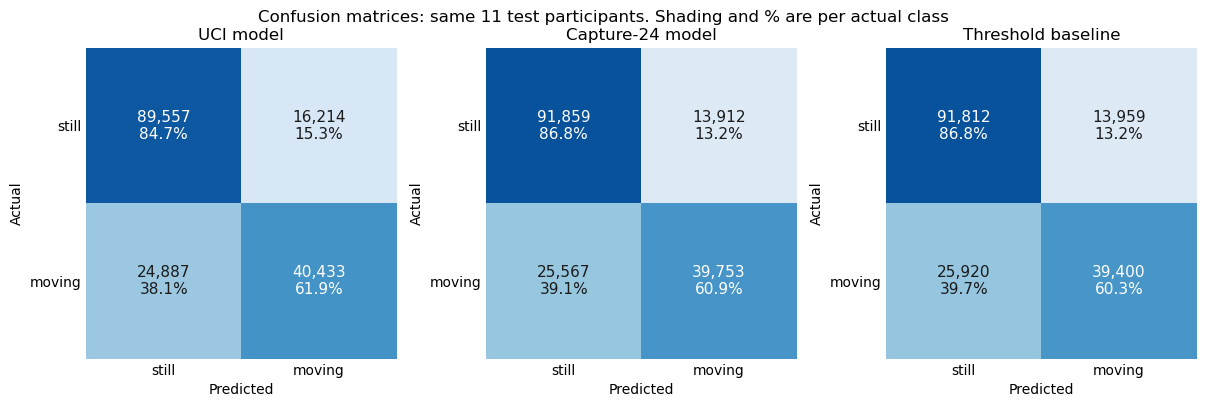

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), constrained_layout=True)

for ax, (name, pred) in zip(axes, predictions.items()):
    counts = confusion_matrix(y_test, pred, labels=[0, 1])
    share = counts / counts.sum(axis=1, keepdims=True)    # share of each true class, so the shading compares fairly
    ax.imshow(share, cmap='Blues', vmin=0, vmax=1)
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f'{counts[row, col]:,}\n{share[row, col]:.1%}', ha='center', va='center', fontsize=11,
                    color='white' if share[row, col] > 0.55 else '#1a1a1a')
    ax.set_xticks([0, 1], CLASS_NAMES)
    ax.set_yticks([0, 1], CLASS_NAMES)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(name)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(f'Confusion matrices: same {test["participant_id"].nunique()} test participants. Shading and % are per actual class')
plt.show()

### Summary of findings

I compared three ways of telling "moving" from "still" on wrist data (Capture-24),
all scored on the same 11 held-out participants:

| | Accuracy | Moving recall | Still recall |
|---|---|---|---|
| UCI model (trained on waist data) | 0.76 | 0.62 | 0.85 |
| Capture-24 model (trained on wrist data) | 0.77 | 0.61 | 0.87 |
| Simple threshold on mag_std | 0.77 | 0.60 | 0.87 |

**All three perform almost the same.** Training on wrist data did not help, and neither
model beat a single threshold. This suggests the limit is the features, not the data or the
model: the 5 magnitude features mainly measure how much the wrist is moving, and every
method draws roughly the same line on that.

**About 39% of moving windows are missed.** Much of "light" activity (standing, slow
pottering) involves little wrist movement, and labels come from photos taken every
20–40 seconds, so some windows are labelled moving during short pauses.

**What this means for SilverGuard:** the inactivity alert looks at 30+ minutes, not single
2.56-second windows, so window-level errors should average out. The simplest option
(threshold or UCI model) is good enough for the MVP, pending a check at the 10–30 minute
level. Accuracy could likely be improved with longer windows and richer features
(frequency, wrist angle), but this isn't needed right now.

In [1]:
# test windows: participant_id, time (window start), y (0 still / 1 moving), pred (model output)
t = test_df.copy()
t['block'] = t['time'].dt.floor('10min')
blocks = t.groupby(['participant_id', 'block']).agg(
    actual=('y', 'mean'), predicted=('pred', 'mean'), n=('y', 'size'))
blocks = blocks[blocks.n >= 100]               # skip blocks with little labelled data

still  = blocks[blocks.actual < 0.1]           # genuinely still 10 minutes
active = blocks[blocks.actual > 0.3]           # genuinely active 10 minutes
plt.hist(still.predicted,  bins=40, alpha=.5, label=f'still blocks (n={len(still)})')
plt.hist(active.predicted, bins=40, alpha=.5, label=f'active blocks (n={len(active)})')
plt.xlabel('share of windows predicted moving'); plt.legend(); plt.show()

NameError: name 'test_df' is not defined

## Part 2 in plain language

This part asks a simple question: can a model tell whether someone is still or moving, on people it has never seen? Sleep was removed, and 11 of the 42 people were set aside as a test group. Three approaches then answered on those same 11 people: the old UCI model, a new forest with the same settings trained on the other 31 people, and a single cut-off rule on `mag_std`, which is how much the movement strength varies within a window.

**All three scored almost the same.** Balanced accuracy, which counts both classes equally, was 0.733 for the UCI model, 0.739 for the Capture-24 model and 0.736 for the cut-off rule. The differences are tiny next to the differences between people (about 0.61 to 0.85 for the Capture-24 model). The three also gave the same answer on about 97% of windows. So training on Capture-24 barely helped, and with these 5 features and this small forest, a model isn't doing much more than one cut-off on `mag_std`. All three catch only about 60% of moving windows. Most of the misses are `light` windows, where only about 53% are caught, compared with about 83% of `moderate-vigorous`. Scores for the 53+ group were about the same as for everyone. These 11 people have now been used, so any future improvements should be chosen using the 31 training people, not by checking this table again.

# Part 3: do the models work at the timescale of the inactivity alert?

The SilverGuard alert fires on 10 to 30 minutes of inactivity, not on one 2.56 s window. A model can be wrong on many single windows and still be reliable once they're averaged over 10 minutes. So this part scores whole blocks of time.

For each block, per person:

- **actual:** share of windows labelled moving
- **predicted:** share of windows the method called moving
- **Still block:** actual below 0.1. **Active block:** actual above 0.3. Blocks in between are left out of the scoring.

The alert rule tested is: flag a block as inactive when `predicted` is at or below a threshold.

- **False alert:** an active block wrongly flagged as inactive.
- **Still detection:** a still block correctly flagged.

Nothing is retrained and these are the same 11 test people as Part 2. This part can run on its own.

**Window start times** already exist: Part 1 saved `window_start` in every parquet. **Window predictions** were not saved in Part 2, so they're regenerated here from the saved models, and the next cell checks that they reproduce the Part 2 scores.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, roc_curve

from features import WIN, FEATURE_NAMES

PARQUET_DIR = Path('../../data/processed/capture24_windows')
UCI_MODEL_PATH = Path('rf_mag_uci.joblib')
UCI_PYTHON = Path(r'C:\Users\syafi\anaconda3\python.exe')
C24_MODEL_PATH = Path('rf_mag_capture24.joblib')
TEST_LIST_PATH = Path('capture24_test_participants.csv')

TO_BINARY = {'sedentary': 0, 'light': 1, 'moderate-vigorous': 1}
OLDER_BIN = '53+'
METHODS = ['UCI model', 'Capture-24 model', 'Threshold baseline']

BLOCK_MINUTES = [10, 30]
MIN_COVERAGE = 0.4     # skip blocks with under 40% of the time covered by labelled, non-sleep windows
STILL_BELOW = 0.1      # actual share of moving windows
ACTIVE_ABOVE = 0.3
WINDOW_SECONDS = WIN / 50

## Regenerate the window predictions

The Capture-24 model is loaded, not refitted. The `mag_std` cut-off wasn't saved in Part 2, so it's recomputed from the training people with the same rule. That is the only use of training people here.

In [2]:
test_ids = pd.read_csv(TEST_LIST_PATH)['participant_id'].tolist()
assert len(test_ids) == 11

files = sorted(PARQUET_DIR.glob('P*.parquet'))
windows = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
windows = windows[windows['label'] != 'sleep'].reset_index(drop=True)
windows['y'] = windows['label'].map(TO_BINARY)
assert windows['y'].notna().all()
windows['y'] = windows['y'].astype(int)

is_test = windows['participant_id'].isin(test_ids)
train, test = windows[~is_test], windows[is_test].reset_index(drop=True)
X_test, y_test = test[FEATURE_NAMES].to_numpy(), test['y'].to_numpy()

# UCI model: unchanged, run by the Python that saved it (see Part 2)
PREDICT = '''
import sys, joblib, numpy as np
m = joblib.load(sys.argv[1])
np.save(sys.argv[3], m.predict(np.load(sys.argv[2])))
'''
env = dict(os.environ)
root = UCI_PYTHON.parent
env['PATH'] = os.pathsep.join([str(root), str(root / 'Library' / 'bin'), str(root / 'Scripts'), env.get('PATH', '')])
with tempfile.TemporaryDirectory() as tmp:
    x_file, pred_file = Path(tmp) / 'x.npy', Path(tmp) / 'pred.npy'
    np.save(x_file, X_test)
    done = subprocess.run([str(UCI_PYTHON), '-c', PREDICT, str(UCI_MODEL_PATH.resolve()), str(x_file), str(pred_file)],
                          capture_output=True, text=True, env=env)
    if done.returncode != 0:
        raise RuntimeError(done.stderr)
    test['UCI model'] = np.load(pred_file)

# Capture-24 model: loaded from disk, not retrained
test['Capture-24 model'] = joblib.load(C24_MODEL_PATH).predict(X_test)

# threshold baseline: same rule as Part 2, on training people only
train_std, y_train = train['mag_std'].to_numpy(), train['y'].to_numpy()
candidates = np.quantile(train_std, np.linspace(0.01, 0.99, 199))
cutoff = candidates[int(np.argmax([((train_std > c).astype(int) == y_train).mean() for c in candidates]))]
test['Threshold baseline'] = (test['mag_std'].to_numpy() > cutoff).astype(int)
print(f'mag_std cutoff: {cutoff:.4f} g')

# these must match the Part 2 table, or the predictions are not the same ones
part2_balanced = {'UCI model': 0.733, 'Capture-24 model': 0.739, 'Threshold baseline': 0.736}
for m in METHODS:
    got = balanced_accuracy_score(y_test, test[m])
    print(f'{m}: window balanced accuracy {got:.3f} (Part 2: {part2_balanced[m]:.3f})')
    assert round(got, 3) == part2_balanced[m]

mag_std cutoff: 0.0955 g
UCI model: window balanced accuracy 0.733 (Part 2: 0.733)
Capture-24 model: window balanced accuracy 0.739 (Part 2: 0.739)
Threshold baseline: window balanced accuracy 0.736 (Part 2: 0.736)


## Step 2: build the blocks

Blocks follow the clock (for example 09:00 to 09:10), separately for each person. Coverage is the share of the block's time filled by labelled, non-sleep windows.

In [3]:
def make_blocks(minutes):
    start = test['window_start'].dt.floor(f'{minutes}min').rename('block_start')
    blocks = test.groupby(['participant_id', 'age_bin', start]).agg(
        windows=('y', 'size'), actual=('y', 'mean'), **{m: (m, 'mean') for m in METHODS}).reset_index()
    blocks['coverage'] = blocks['windows'] * WINDOW_SECONDS / (minutes * 60)
    blocks['kind'] = np.select([blocks['actual'] < STILL_BELOW, blocks['actual'] > ACTIVE_ABOVE], ['still', 'active'], 'in between')
    return blocks


all_blocks = {minutes: make_blocks(minutes) for minutes in BLOCK_MINUTES}
blocks = {minutes: b[b['coverage'] >= MIN_COVERAGE].reset_index(drop=True) for minutes, b in all_blocks.items()}

for minutes in BLOCK_MINUTES:
    # windows belong to the block they start in, so a block can hold one window more than fits exactly (coverage just over 1)
    assert blocks[minutes]['windows'].max() <= np.ceil(minutes * 60 / WINDOW_SECONDS)

rows = {}
for minutes, b in blocks.items():
    older = b['age_bin'] == OLDER_BIN
    rows[f'{minutes} min, all'] = {'skipped (low coverage)': len(all_blocks[minutes]) - len(b), 'kept': len(b), **b['kind'].value_counts().to_dict()}
    rows[f'{minutes} min, 53+'] = {'skipped (low coverage)': np.nan, 'kept': older.sum(), **b.loc[older, 'kind'].value_counts().to_dict()}
print(pd.DataFrame(rows).T[['skipped (low coverage)', 'kept', 'still', 'active', 'in between']].to_string())

             skipped (low coverage)   kept  still  active  in between
10 min, all                    64.0  804.0  382.0   352.0        70.0
10 min, 53+                     NaN  636.0  275.0   301.0        60.0
30 min, all                    36.0  274.0  106.0   138.0        30.0
30 min, 53+                     NaN  217.0   75.0   118.0        24.0


## Step 3: how well does `predicted` separate still blocks from active blocks?

- **ROC AUC:** pick one still block and one active block at random. AUC is the chance the still one has the lower `predicted`. 0.5 is coin-flipping and 1.0 is perfect separation.
- **Threshold:** the value with the biggest gap between still detection and false alerts (Youden's J). When values tie, the one with fewer false alerts wins.

**These thresholds are chosen on the same blocks they're scored on,** so the rates are a best case. Treat them as a description of this data, not as settings to put on the device.

In [4]:
def separate(b, method):
    '''AUC, the best threshold on predicted, and what happens at that threshold.'''
    two = b[b['kind'].isin(['still', 'active'])]
    is_still = (two['kind'] == 'still').to_numpy()
    pred = two[method].to_numpy()

    # lower predicted means more likely still, so roc_curve scores on -predicted
    fpr, tpr, thr = roc_curve(is_still, -pred, drop_intermediate=False)
    finite = np.isfinite(thr)
    best = np.flatnonzero(finite)[np.argmax((tpr - fpr)[finite])]
    threshold = -thr[best]

    flagged = pred <= threshold
    out = {'AUC': roc_auc_score(is_still, -pred), 'threshold': threshold,
           'false-alert rate': flagged[~is_still].mean(), 'still-detection rate': flagged[is_still].mean(),
           'false alerts': int(flagged[~is_still].sum()), 'active blocks': int((~is_still).sum()),
           'still flagged': int(flagged[is_still].sum()), 'still blocks': int(is_still.sum())}
    assert np.isclose(out['false-alert rate'], fpr[best]) and np.isclose(out['still-detection rate'], tpr[best])
    return out


GROUPS = {'All test participants': lambda b: b, f'{OLDER_BIN} only': lambda b: b[b['age_bin'] == OLDER_BIN]}
evaluated = {(group, m, minutes): separate(pick(blocks[minutes]), m)
             for group, pick in GROUPS.items() for m in METHODS for minutes in BLOCK_MINUTES}

counts = pd.DataFrame(evaluated).T
counts.index.names = ['group', 'method', 'block (min)']
print('Counts at each threshold:\n')
print(counts[['threshold', 'false alerts', 'active blocks', 'still flagged', 'still blocks']]
      .assign(threshold=lambda d: d['threshold'].astype(float).round(3)).to_string())

Counts at each threshold:

                                                      threshold  false alerts  active blocks  still flagged  still blocks
group                 method             block (min)                                                                     
All test participants UCI model          10               0.357          87.0          352.0          343.0         382.0
                                         30               0.341          34.0          138.0           99.0         106.0
                      Capture-24 model   10               0.360          94.0          352.0          365.0         382.0
                                         30               0.273          25.0          138.0           97.0         106.0
                      Threshold baseline 10               0.344          91.0          352.0          360.0         382.0
                                         30               0.298          30.0          138.0          100.0         106

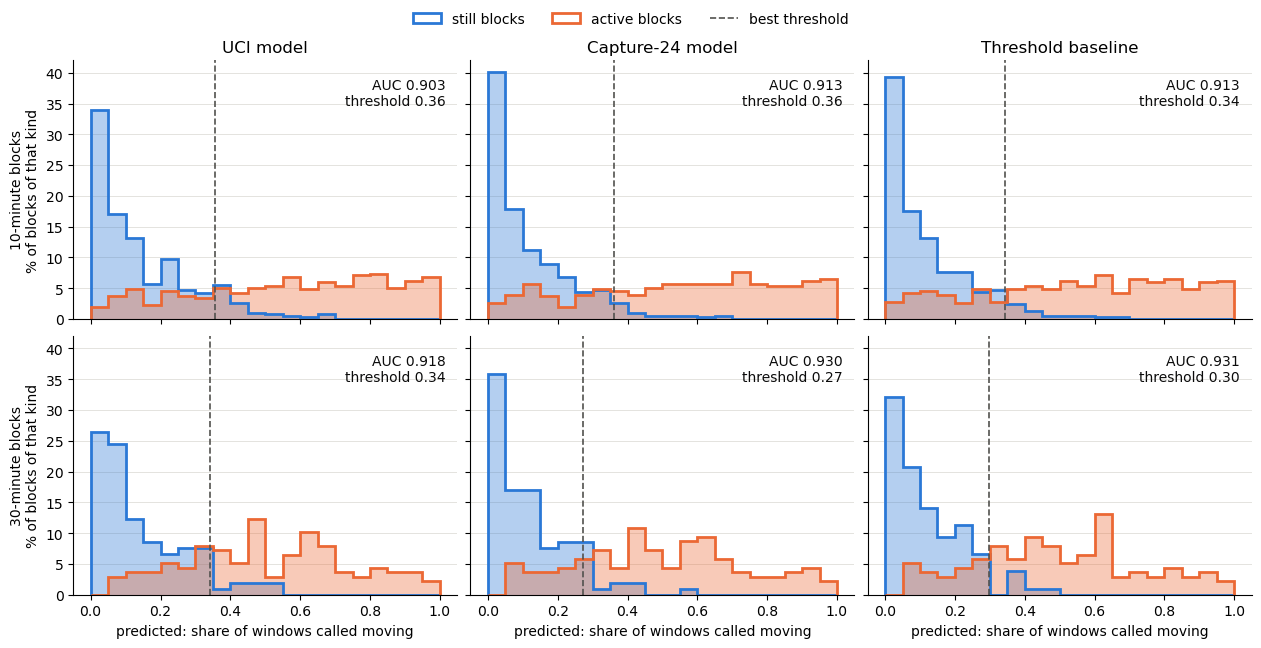

In [5]:
STILL_COLOUR, ACTIVE_COLOUR = '#2a78d6', '#eb6834'
bins = np.linspace(0, 1, 21)

fig, axes = plt.subplots(len(BLOCK_MINUTES), len(METHODS), figsize=(12.5, 6.4), sharex=True, sharey=True, constrained_layout=True)

for r, minutes in enumerate(BLOCK_MINUTES):
    for c, m in enumerate(METHODS):
        ax = axes[r, c]
        res = evaluated[('All test participants', m, minutes)]
        for kind, colour in [('still', STILL_COLOUR), ('active', ACTIVE_COLOUR)]:
            values = blocks[minutes].loc[blocks[minutes]['kind'] == kind, m]
            percent = np.full(len(values), 100 / len(values))     # % of that kind, because there are more still blocks
            ax.hist(values, bins, weights=percent, histtype='stepfilled', color=colour, alpha=0.35)
            ax.hist(values, bins, weights=percent, histtype='step', color=colour, linewidth=2, label=f'{kind} blocks')
        ax.axvline(res['threshold'], color='#52514e', linestyle='--', linewidth=1.2, label='best threshold')
        ax.text(0.97, 0.93, f"AUC {res['AUC']:.3f}\nthreshold {res['threshold']:.2f}", transform=ax.transAxes, ha='right', va='top', fontsize=10, color='#0b0b0b')
        ax.grid(axis='y', color='#e4e3df', linewidth=0.7)
        ax.set_axisbelow(True)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        if r == 0:
            ax.set_title(m)
        if r == len(BLOCK_MINUTES) - 1:
            ax.set_xlabel('predicted: share of windows called moving')
        if c == 0:
            ax.set_ylabel(f'{minutes}-minute blocks\n% of blocks of that kind')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncols=3, frameon=False)
plt.show()

## Steps 4 and 5: summary table

Every row is scored on still and active blocks only. The 53+ columns use blocks from the 53+ test people, with their own threshold.

In [6]:
COLUMNS = ['AUC', 'threshold', 'false-alert rate', 'still-detection rate']
summary = pd.DataFrame(
    {(m, f'{minutes} min'): {(group, col): evaluated[(group, m, minutes)][col] for group in GROUPS for col in COLUMNS}
     for m in METHODS for minutes in BLOCK_MINUTES}).T
summary.columns = pd.MultiIndex.from_tuples(summary.columns)
summary.index.names = ['method', 'block']
summary.astype(float).round(3)

All test participants                             \
                                            AUC threshold false-alert rate   
method             block                                                     
UCI model          10 min                 0.903     0.357            0.247   
                   30 min                 0.918     0.341            0.246   
Capture-24 model   10 min                 0.913     0.360            0.267   
                   30 min                 0.930     0.273            0.181   
Threshold baseline 10 min                 0.913     0.344            0.259   
                   30 min                 0.931     0.298            0.217   

                                               53+ only            \
                          still-detection rate      AUC threshold   
method             block                                            
UCI model          10 min                0.898    0.906     0.251   
                   30 min                0.934    0.925     0.212   
Capture-24 model   10 min                0.955    0.914     0.255   
                   30 min                0.915    0.934     0.209   
Threshold baseline 10 min                0.942    0.915     0.250   
                   30 min                0.943    0.937     0.214   

                                                                 
                          false-alert rate still-detection rate  
method             block                                         
UCI model          10 min            0.196                0.844  
                   30 min            0.127                0.827  
Capture-24 model   10 min            0.199                0.891  
                   30 min            0.144                0.893  
Threshold baseline 10 min            0.203                0.891  
                   30 min            0.153                0.907

## Extra check: how far can the table above be trusted?

This wasn't in the brief, but the table's thresholds are picked on the same blocks they score, so it's a best case. This cell asks four things:

- **New person:** what happens when each person is scored with a threshold chosen on the other 10?
- **53+:** what happens when the 53+ blocks use the same threshold as everyone, rather than their own?
- **Person to person:** how much does the AUC vary?
- **Sleep and in-between blocks:** how often would the alert fire on the blocks left out of the scoring?

In [7]:
check = {}
for minutes in BLOCK_MINUTES:
    b = blocks[minutes]
    two = b[b['kind'].isin(['still', 'active'])]
    hours = len(b) * minutes / 60
    for m in METHODS:
        pooled = evaluated[('All test participants', m, minutes)]
        thr = pooled['threshold']

        # new person: threshold from the other 10, scored on the person left out
        false_alerts = still_flagged = 0
        for pid in test_ids:
            t = separate(two[two['participant_id'] != pid], m)['threshold']
            one = two[two['participant_id'] == pid]
            false_alerts += (one.loc[one['kind'] == 'active', m] <= t).sum()
            still_flagged += (one.loc[one['kind'] == 'still', m] <= t).sum()

        older = two[two['age_bin'] == OLDER_BIN]
        person_auc = [roc_auc_score(g['kind'] == 'still', -g[m]) for _, g in two.groupby('participant_id')]
        check[(m, f'{minutes} min')] = {
            'new person: false-alert rate': false_alerts / (two['kind'] == 'active').sum(),
            'new person: still detection': still_flagged / (two['kind'] == 'still').sum(),
            '53+ at everyone\'s threshold: false-alert rate': (older.loc[older['kind'] == 'active', m] <= thr).mean(),
            '53+ at everyone\'s threshold: still detection': (older.loc[older['kind'] == 'still', m] <= thr).mean(),
            'lowest person AUC': min(person_auc), 'highest person AUC': max(person_auc),
            'false alerts per labelled hour': pooled['false alerts'] / hours,
            'in-between blocks flagged': (b.loc[b['kind'] == 'in between', m] <= thr).mean(),
        }
print(pd.DataFrame(check).T.astype(float).round(3).T.to_string())

# sleep was dropped from the scoring. What would the Capture-24 rule do during sleep?
sleep = pd.concat([pd.read_parquet(PARQUET_DIR / f'{p}.parquet') for p in test_ids], ignore_index=True)
sleep = sleep[sleep['label'] == 'sleep'].reset_index(drop=True)
sleep['pred'] = joblib.load(C24_MODEL_PATH).predict(sleep[FEATURE_NAMES].to_numpy())
print()
for minutes in BLOCK_MINUTES:
    g = sleep.groupby(['participant_id', sleep['window_start'].dt.floor(f'{minutes}min')])['pred'].agg(['size', 'mean'])
    g = g[g['size'] * WINDOW_SECONDS / (minutes * 60) >= MIN_COVERAGE]
    thr = evaluated[('All test participants', 'Capture-24 model', minutes)]['threshold']
    print(f'sleep-only {minutes}-minute blocks: {len(g)}, flagged inactive by the Capture-24 rule: {(g["mean"] <= thr).mean():.1%}')

                                              UCI model Capture-24 model Threshold baseline UCI model Capture-24 model Threshold baseline
                                                 10 min           10 min             10 min    30 min           30 min             30 min
new person: false-alert rate                      0.298            0.264              0.261     0.239            0.217              0.217
new person: still detection                       0.848            0.903              0.874     0.783            0.830              0.830
53+ at everyone's threshold: false-alert rate     0.279            0.296              0.286     0.263            0.203              0.237
53+ at everyone's threshold: still detection      0.905            0.956              0.949     0.933            0.920              0.933
lowest person AUC                                 0.615            0.688              0.685     0.533            0.667              0.653
highest person AUC                


sleep-only 10-minute blocks: 395, flagged inactive by the Capture-24 rule: 99.5%
sleep-only 30-minute blocks: 135, flagged inactive by the Capture-24 rule: 100.0%


### Summary: block-level check (10–30 minutes)

Single 2.56 s windows were only about 74% right (balanced). Since the SilverGuard
inactivity alert looks at longer stretches, I grouped windows into 10- and 30-minute
blocks and checked whether still and active blocks can be told apart.

**Longer stretches help a lot.** All three methods separate still from active blocks
about 9 times in 10 (AUC 0.90–0.93). The three methods are still tied, so the simple
`mag_std` threshold is the best choice for the device: easiest to run and explain.

**Not reliable enough as a one-block alert.** With a threshold chosen on other people,
22–30% of active blocks are wrongly flagged inactive, about 0.2 false alerts per hour
at 30 minutes (roughly 3 per waking day). Results also vary a lot by person
(AUC from about 0.53 to 1.0), and the 53+ group is no better than everyone else.
Sleep is flagged inactive almost 100% of the time, as expected.

**What this means for the design:**
- Trigger "prolonged inactivity" only after several consecutive inactive blocks
  (e.g. 60–120 minutes), not one.
- Make the first response a gentle voice check-in, escalating only if there is no answer.
- Pause the inactivity alert during sleep (sleep rule or time-of-day window).
- Set the final threshold on our own watch recordings; these thresholds were chosen
  on the 11 test participants and should not be used as device settings.

**Conclusion:** the activity detector is good enough at the 10–30 minute level. Its
false-alert rate is handled by how the alert is designed, not by improving the model.

## Part 3 in plain language

**Looking at longer stretches of time helps a lot.** Single windows were only right about 74% of the time on a balanced score. Across 10 to 30 minutes, all three methods tell a still block from an active one about 9 times in 10 (AUC 0.90 to 0.93), and 30-minute blocks are slightly better than 10-minute ones. The three methods are tied again: the Capture-24 model and the plain `mag_std` cut-off differ by 0.001 in AUC or less. So these results give no reason to choose the forest over the cut-off rule.

**Telling blocks apart is not the same as being a reliable alert.** Even at the best threshold, 18 to 27% of active blocks get wrongly flagged as inactive, while 90 to 96% of still blocks are caught. With a threshold chosen on other people, which is closer to real use, false alerts are 22 to 30% and still detection is 78 to 90%. The 53+ columns look better (13 to 20% false alerts), but only because they use their own lower threshold, which also catches fewer still blocks. At everyone's threshold, the 53+ group is no better (20 to 30%). Results also vary a lot by person: at 10 minutes, the Capture-24 model's AUC is 0.998 for P107 but 0.688 for P137. Finally, this test leaves two things out. Sleep was removed, and the rule flags nearly every sleep block as inactive, so it needs a way of knowing the person is awake. Blocks between 0.1 and 0.3 were also not scored. These thresholds were chosen on the 11 test people, so don't use them as device settings.